# Week 3 - Noise filtering
Necessary imports

In [1]:
from __future__ import annotations
import cv2
import matplotlib.pyplot as plt
import pickle
from dataclasses import dataclass
from pathlib import Path
import random
import math

import numpy as np
from skimage.filters import threshold_otsu
from skimage.metrics import structural_similarity
from scipy.ndimage import gaussian_filter1d, binary_fill_holes, gaussian_filter1d

In [2]:
def find_project_root():
    for directory in (Path.cwd(), *Path.cwd().parents):
        if (directory / "data").is_dir() and (directory / "src").is_dir():
            return directory
    raise FileNotFoundError("Could not find the project root")


ROOT = find_project_root()
DATA_DIR = ROOT / "data"

## 0. Image and ground truth loading
Code snippet from week1 code so it stays with a persistent method

In [3]:
@dataclass(frozen=True)
class ImageDataset:
    """Image paths paired with integer IDs in deterministic filename order."""

    paths: tuple[Path, ...]
    ids: np.ndarray

    def __len__(self) -> int:
        return len(self.paths)


def image_id(path: Path) -> int:
    """Parse IDs from both `00012.jpg` and `bbdd_00012.jpg`."""
    return int(path.stem.rsplit("_", 1)[-1])


def load_image_dataset(directory: str | Path) -> ImageDataset:
    directory = Path(directory)
    # Sorting is essential: submission row i must correspond to query image i.
    paths = tuple(sorted(directory.glob("*.jpg")))
    if not paths:
        raise FileNotFoundError(f"No JPG images found in {directory}")
    ids = np.asarray([image_id(path) for path in paths], dtype=int)
    if len(np.unique(ids)) != len(ids):
        raise ValueError(f"Duplicate image IDs found in {directory}")
    return ImageDataset(paths=paths, ids=ids)


def load_ground_truth(path: str | Path) -> list[list[int]]:
    with Path(path).open("rb") as stream:
        values = pickle.load(stream)
    return [[int(image_id) for image_id in relevant] for relevant in values]


In [4]:
train_dataset = load_image_dataset(f"{DATA_DIR}/qsd1_w3")
non_augmented_data = load_image_dataset(f"{DATA_DIR}/qsd1_w3/non_augmented")
ground_truth = load_ground_truth(f"{DATA_DIR}/qsd1_w3/gt_corresps.pkl")

In [5]:
train_dataset.ids

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29])

## Noise observation and analysis
Analyzing the type of noise that is present in the images will help us find the correct filters to reduce it successfully.
To do so we must observe the images and find which noise patterns emerge when plotted.

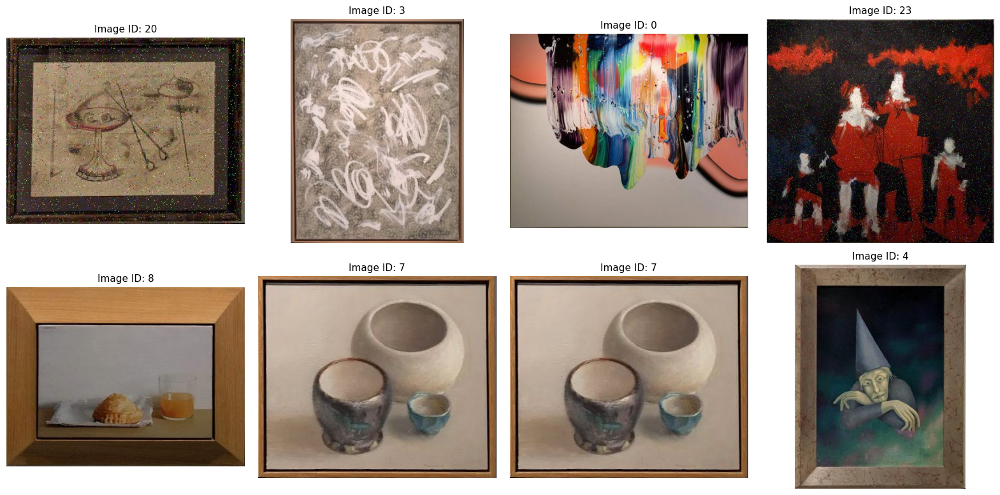

In [6]:
random.seed(42)
n_images = 8

n_cols = 4 
n_rows = math.ceil(n_images / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(n_cols * 4, n_rows * 4)
)

# Make axes iterable even if there's only one row or column
axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for i in range(n_images):
    random_index = random.randint(0, len(train_dataset.paths) - 1)
    image_path = train_dataset.paths[random_index]
    image_id_value = train_dataset.ids[random_index]

    # Load image and convert BGR to RGB
    image = cv2.imread(str(image_path))
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    axes[i].imshow(image_rgb)
    axes[i].set_title(f"Image ID: {image_id_value}", fontsize=11)
    axes[i].axis("off")

# Hide unused grid cells
for j in range(n_images, len(axes)):
    axes[j].axis("off")

plt.tight_layout(pad=1.5)
plt.show()


In this sample we can see that not all the images have noise. Before analysing any filter, we compare every image of `train_dataset` with its clean version in `non_augmented`. We measure only the high-frequency part of the difference, so colour or brightness changes are not counted as noise, and we use Otsu's threshold to split the dataset into noisy and non-noisy images. The filter analysis that follows uses only the noisy subset.

In [7]:
clean_by_id = dict(zip(non_augmented_data.ids.tolist(), non_augmented_data.paths))

def read_rgb(path: Path) -> np.ndarray:
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f"Could not read image: {path}")
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

def noise_score(noisy_path, clean_path, sigma=3):
    diff = read_rgb(noisy_path).astype(np.float32) - read_rgb(clean_path).astype(np.float32)
    return (diff - cv2.GaussianBlur(diff, (0, 0), sigma)).std()   # high-frequency part only

scores = np.array([noise_score(p, clean_by_id[int(i)])
                   for p, i in zip(train_dataset.paths, train_dataset.ids)])
threshold = 10 ** threshold_otsu(np.log10(scores + 1e-6))
noisy_mask = scores > threshold
noisy_idx = np.flatnonzero(noisy_mask)

def subset_dataset(ds, mask):
    idx = np.flatnonzero(mask)
    return ImageDataset(tuple(ds.paths[i] for i in idx), ds.ids[idx])

noisy_subset = subset_dataset(train_dataset, noisy_mask)
clean_subset = subset_dataset(train_dataset, ~noisy_mask)
print(f"{len(noisy_subset)} noisy / {len(clean_subset)} without noise (threshold = {threshold:.2f})")

21 noisy / 9 without noise (threshold = 0.00)


Now let's analyse which type of noise have the `noisy_images`. To do it, we can plot the original vs noisy image and it's difference.

--- Image ID 5 ---


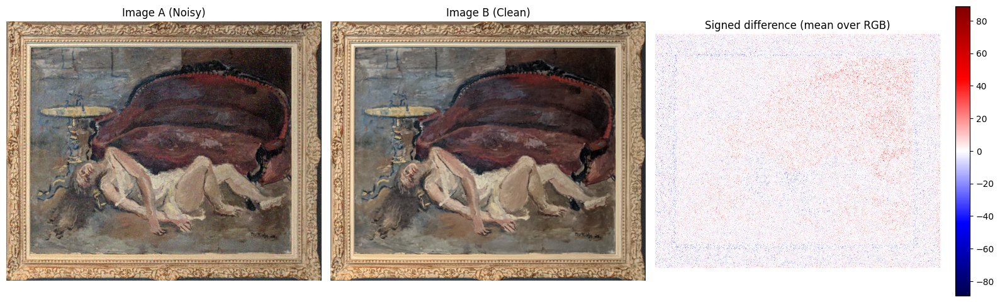

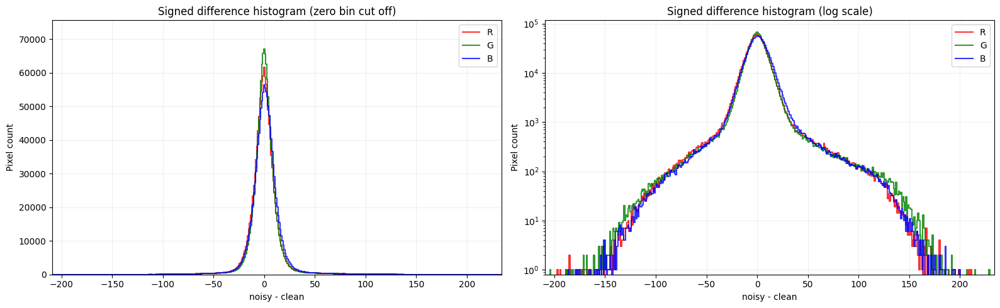

--- Image ID 25 ---


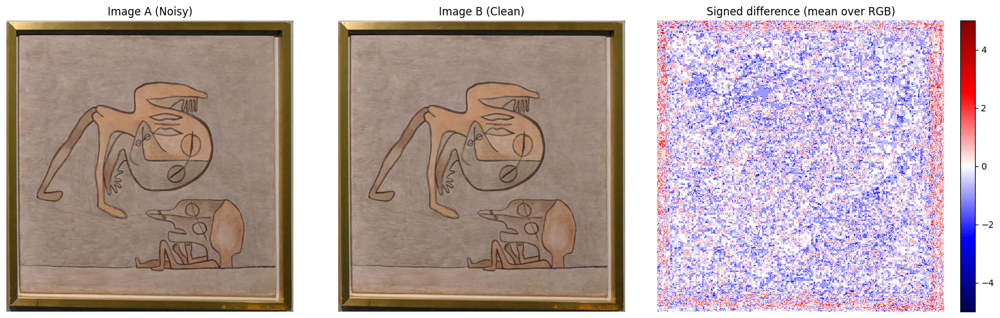

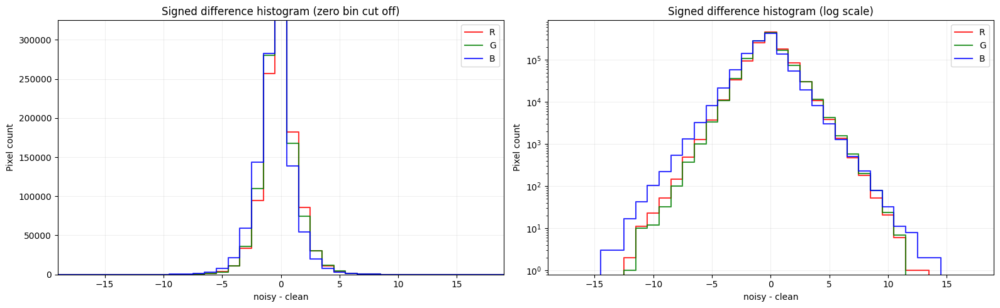

--- Image ID 3 ---


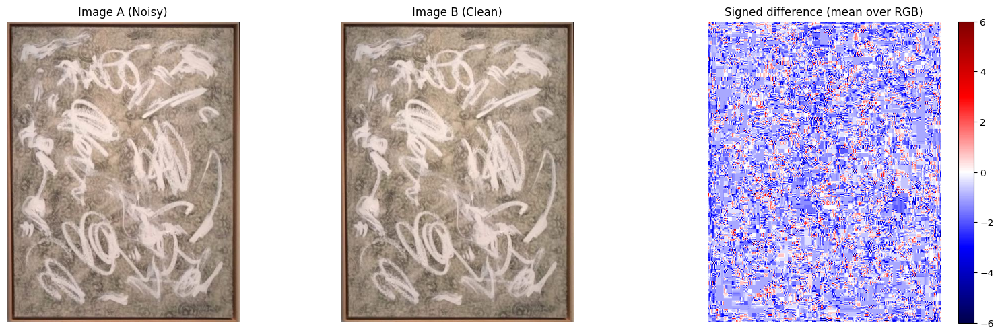

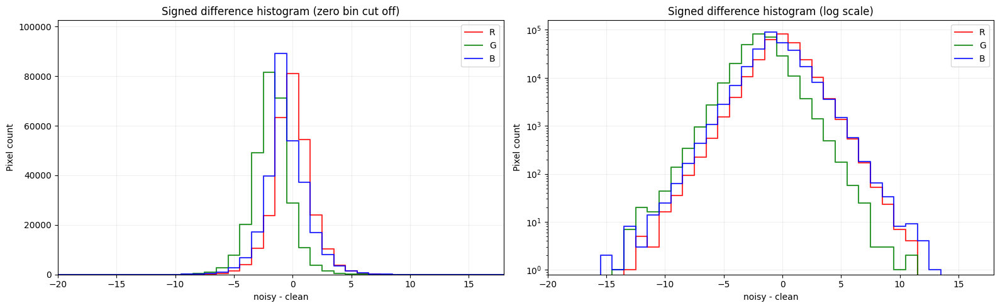

--- Image ID 18 ---


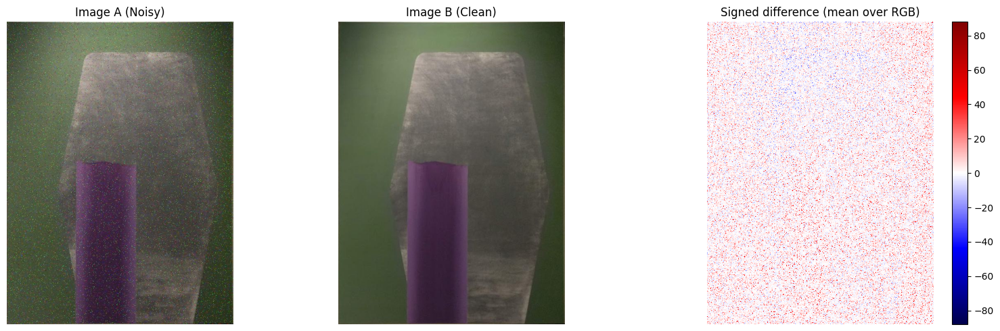

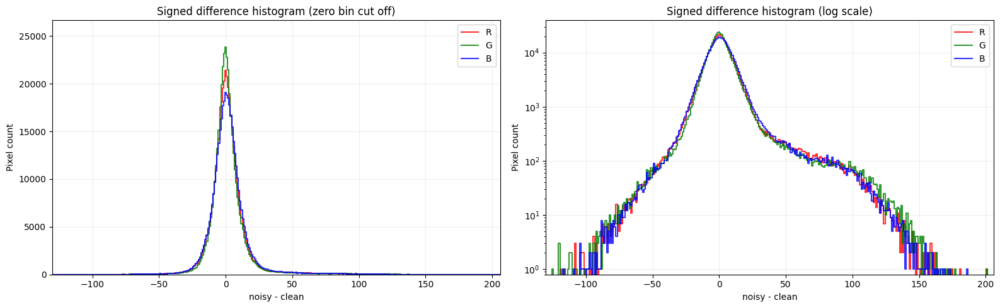

--- Image ID 2 ---


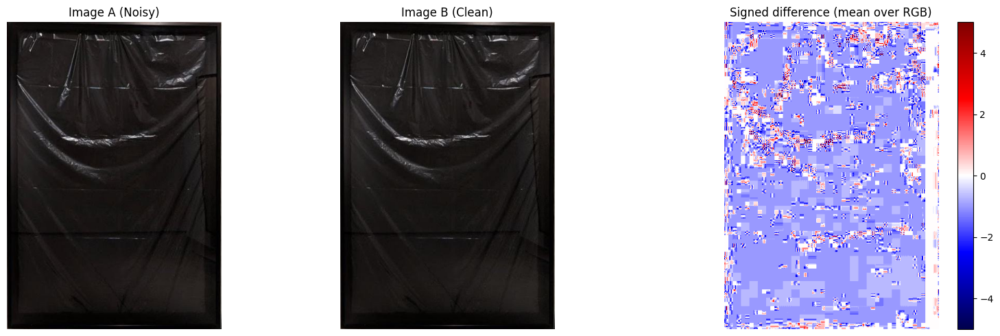

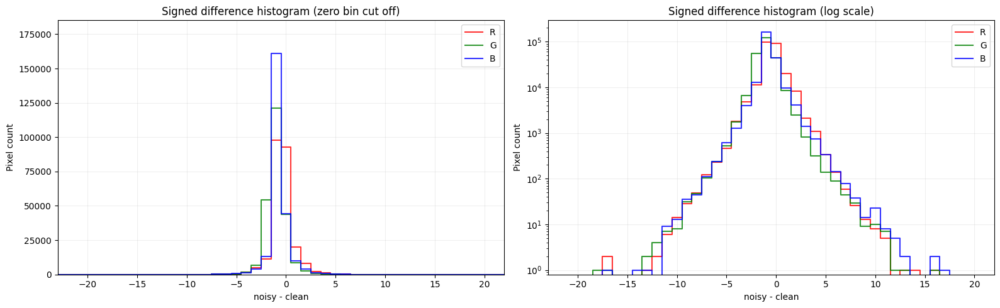

--- Image ID 0 ---


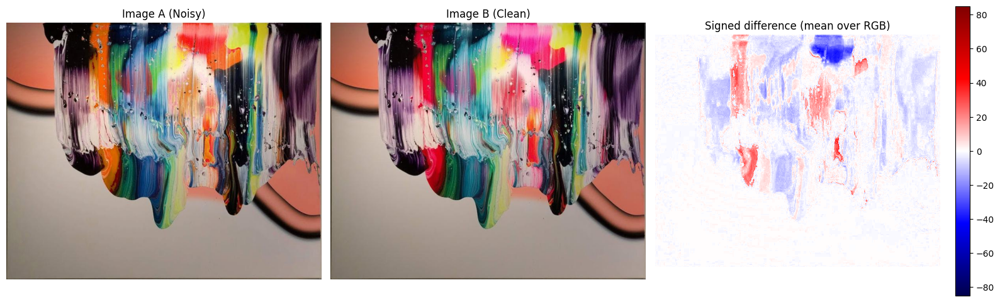

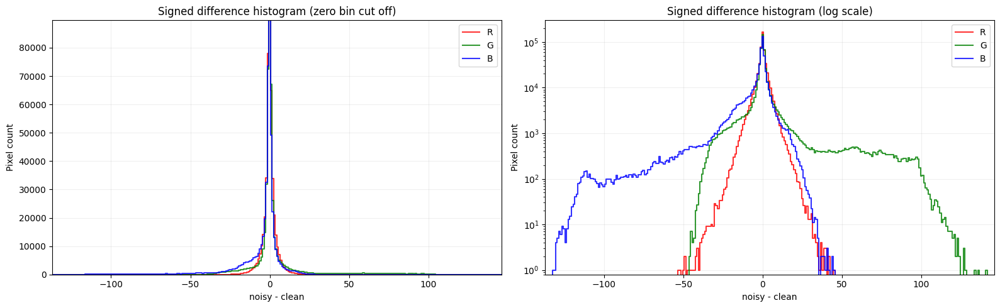

--- Image ID 23 ---


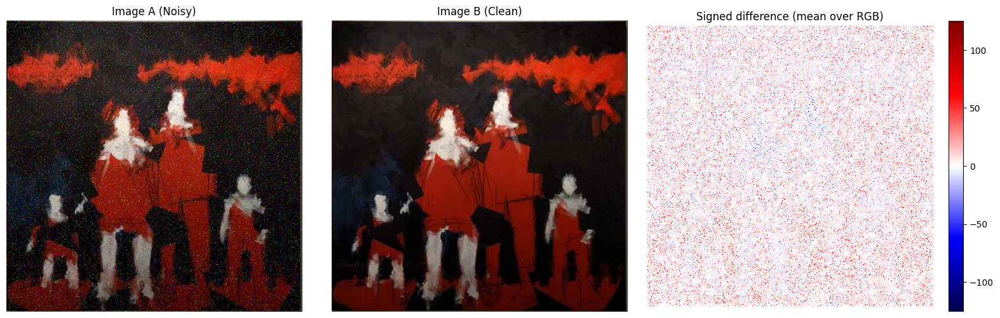

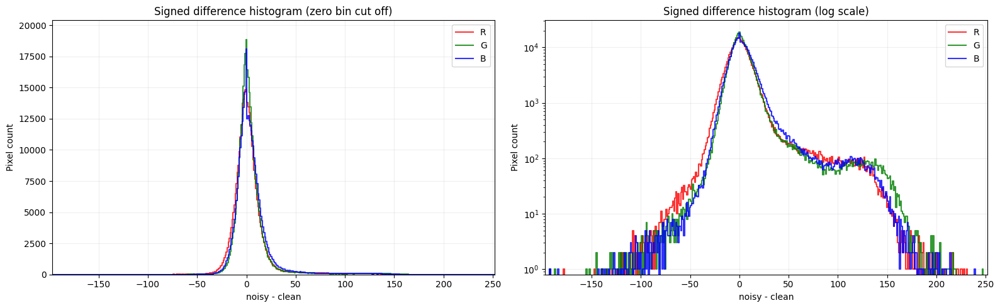

--- Image ID 29 ---


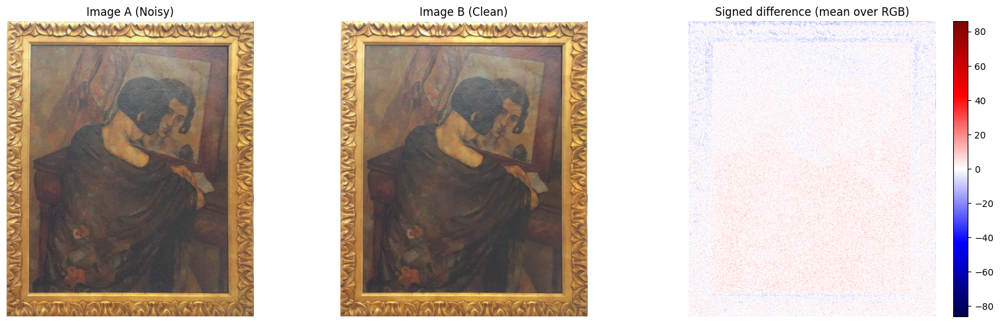

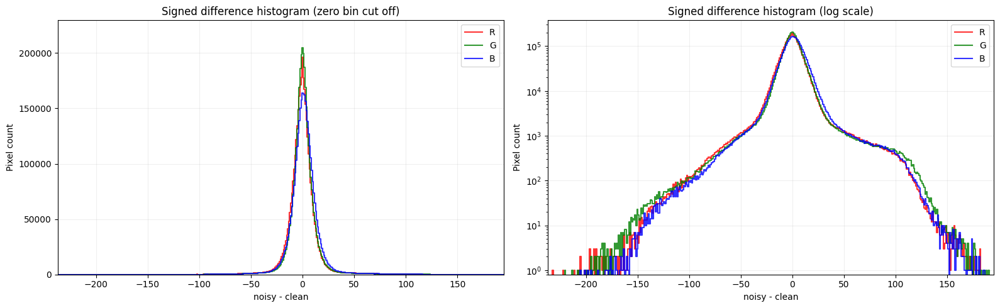

In [8]:
def compute_histograms_and_difference(a, b, plot=False):
    """
    Display noisy image, clean image, their signed difference,
    and the per-channel histograms of the difference.

    Returns
    -------
    image_a, image_b, difference (signed, noisy - clean), difference_histogram
    """

    def load_rgb(path):
        image = cv2.imread(str(path), cv2.IMREAD_COLOR)
        if image is None:
            raise ValueError(f"Could not load image: {path}")
        return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    image_a = load_rgb(a)
    image_b = load_rgb(b)

    if image_a.shape != image_b.shape:
        raise ValueError(
            f"Image dimensions differ: {image_a.shape} vs {image_b.shape}"
        )

    # Signed difference (int16 avoids uint8 wraparound)
    difference = image_a.astype(np.int16) - image_b.astype(np.int16)

    # One integer bin per possible difference value: -255 ... 255
    bin_edges = np.arange(-255.5, 256.5, 1.0)
    values = np.arange(-255, 256)

    difference_histogram = np.concatenate([
        np.histogram(difference[:, :, c].ravel(), bins=bin_edges)[0]
        for c in range(3)
    ])

    if plot:
        n = len(values)
        hists = [difference_histogram[c * n:(c + 1) * n] for c in range(3)]
        colors = ["red", "green", "blue"]
        names = ["R", "G", "B"]

        # ---------- Images ----------
        lim = max(np.percentile(np.abs(difference), 99.5), 1)

        fig, axes = plt.subplots(1, 3, figsize=(16, 5))
        axes[0].imshow(image_a)
        axes[0].set_title("Image A (Noisy)")
        axes[1].imshow(image_b)
        axes[1].set_title("Image B (Clean)")
        im = axes[2].imshow(difference.mean(axis=2), cmap="seismic",
                            vmin=-lim, vmax=lim)
        axes[2].set_title("Signed difference (mean over RGB)")
        plt.colorbar(im, ax=axes[2], fraction=0.046)
        for ax in axes:
            ax.axis("off")
        plt.tight_layout()
        plt.show()

        # ---------- Histograms ----------
        # Zoom the x-axis onto where the data actually lives
        nonzero = np.where(sum(hists) > 0)[0]
        x_min = max(values[nonzero.min()] - 5, -255)
        x_max = min(values[nonzero.max()] + 5, 255)

        fig, axes = plt.subplots(1, 2, figsize=(16, 5))

        for h, col, name in zip(hists, colors, names):
            axes[0].step(values, h, where="mid", color=col, alpha=0.8, label=name)
            axes[1].step(values, h, where="mid", color=col, alpha=0.8, label=name)

        # Left: linear scale, with the zero bin cut off so the rest is visible
        peak_wo_zero = max(np.delete(h, 255).max() for h in hists)
        axes[0].set_ylim(0, peak_wo_zero * 1.15)
        axes[0].set_title("Signed difference histogram (zero bin cut off)")

        # Right: log scale, shows the tails
        axes[1].set_yscale("log")
        axes[1].set_ylim(bottom=0.8)
        axes[1].set_title("Signed difference histogram (log scale)")

        for ax in axes:
            ax.set_xlim(x_min, x_max)
            ax.set_xlabel("noisy - clean")
            ax.set_ylabel("Pixel count")
            ax.grid(alpha=0.2)
            ax.legend()

        plt.tight_layout()
        plt.show()

    return image_a, image_b, difference, difference_histogram

# let's choose 4 random examples
for i in random.sample(range(len(noisy_subset)), 8):
    path, img_id = noisy_subset.paths[i], noisy_subset.ids[i]
    print(f"--- Image ID {img_id} ---")
    compute_histograms_and_difference(path, clean_by_id[int(img_id)], plot=True)

The signed difference histograms of 8 random noisy images show that the noise is not identical across the dataset. In the signed difference histogram with the zero bin cut off, all the histograms have a *Gaussian-like shape*: a compact bell centred at 0 with a small deviation $\sigma$. However, in the log-scale histogram two components appear:

- **Gaussian-like core**: it has the shape of a parabola, which is the signature of Gaussian noise. It is present in all the noisy images.

- **Heavy tails**: in some images the log-scale histogram shows a plateau, usually on the positive side (in some images it is the same in the 3 channels and in others each channel has a different distribution). This could be the result of impulse/salt-and-pepper noise: a corrupted pixel is set to an extreme value (0 or 255), so the difference between the noisy and the original pixel is $255 - \text{clean}$ or $0 - \text{clean}$, which is spread over a wide range because it depends on the original intensity of each pixel.

As the noise is a mixture, we try two families of filters (linear and non-linear). Linear filters (mean and Gaussian) are the natural choice for Gaussian noise, but they blur edges and textures and spread impulses instead of removing them. The median filter is robust to outliers, and we also try the bilateral and non-local means filters. We apply all of them and compare the results.

## Filter comparison

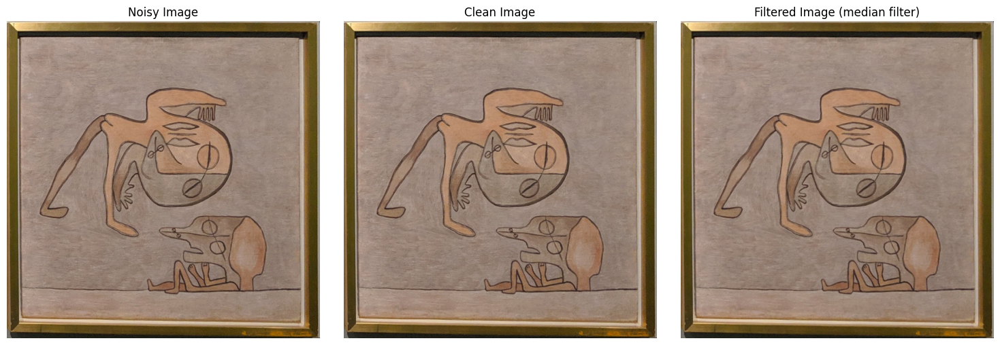

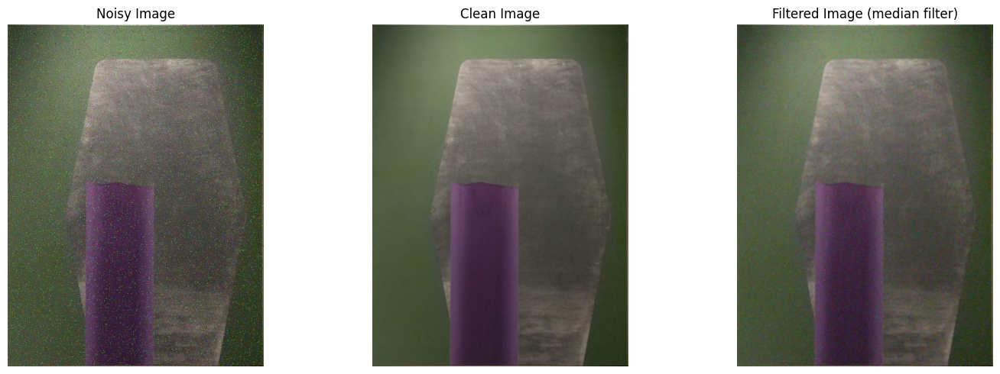

In [9]:
# gaussian like core example
noisy_image1 = train_dataset.paths[25]
clean_image1 = non_augmented_data.paths[25]

image_a1, image_b1, difference, difference_histogram = (
    compute_histograms_and_difference(noisy_image1, clean_image1, plot=False))
filtered_image_median = cv2.medianBlur(image_a1, 3)

# compare the original noisy image, the clean image, and the filtered image
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(image_a1)
plt.title("Noisy Image")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(image_b1)
plt.title("Clean Image")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(filtered_image_median)
plt.title("Filtered Image (median filter)")
plt.axis("off")
plt.tight_layout()
plt.show()


# heavy tails example
noisy_image1 = train_dataset.paths[18]
clean_image1 = non_augmented_data.paths[18]

image_a2, image_b2, difference, difference_histogram = (
    compute_histograms_and_difference(noisy_image1, clean_image1, plot=False))

filtered_image_median = cv2.medianBlur(image_a2, 3)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(image_a2)
plt.title("Noisy Image")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(image_b2)
plt.title("Clean Image")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(filtered_image_median)
plt.title("Filtered Image (median filter)")
plt.axis("off")
plt.tight_layout()
plt.show()

## Filter performance analysis

In [10]:
filters = {
    "Median Filter": lambda img: cv2.medianBlur(img, 3),
    "Gaussian Filter": lambda img: cv2.GaussianBlur(img, (3, 3), 0),
    "Mean Filter": lambda img: cv2.blur(img, (3, 3)),
    "Bilateral Filter": lambda img: cv2.bilateralFilter(img, 9, 75, 75),
    "Non local Means Filter": lambda img: cv2.fastNlMeansDenoisingColored(img, None, 10, 10, 7, 21),}

## Filter evaluation against the non-augmented dataset
Each noisy image is filtered and compared with the clean image having the same numeric ID. The plots show the mean and standard deviation across the dataset.

In [11]:
def evaluate_filters(
    noisy_dataset: ImageDataset,
    clean_dataset: ImageDataset,
    filter_functions: dict[str, callable],
) -> dict[str, dict[str, np.ndarray | float]]:
    """Compute per-image MSE and SSIM for every filter."""
    clean_by_id = dict(zip(clean_dataset.ids.tolist(), clean_dataset.paths))
    missing_ids = sorted(set(noisy_dataset.ids.tolist()) - set(clean_by_id))
    if missing_ids:
        raise ValueError(f"No clean counterpart for image IDs: {missing_ids}")

    metrics = {}
    for filter_name, filter_function in filter_functions.items():
        mse_values = []
        ssim_values = []
        for noisy_path, image_id_value in zip(noisy_dataset.paths, noisy_dataset.ids):
            noisy = read_rgb(noisy_path)
            clean = read_rgb(clean_by_id[int(image_id_value)])
            if noisy.shape != clean.shape:
                raise ValueError(
                    f"Image shape mismatch for ID {image_id_value}: "
                    f"{noisy.shape} vs {clean.shape}"
                )

            filtered = filter_function(noisy)
            mse_values.append(np.mean((filtered.astype(np.float32) - clean) ** 2))
            ssim_values.append(
                structural_similarity(clean, filtered, channel_axis=2, data_range=255)
            )

        metrics[filter_name] = {
            "mse": np.asarray(mse_values),
            "ssim": np.asarray(ssim_values),
        }
    return metrics


filter_metrics = evaluate_filters(noisy_subset, non_augmented_data, filters)

summary = []
for filter_name, values in filter_metrics.items():
    summary.append({
        "Filter": filter_name,
        "MSE mean": values["mse"].mean(),
        "MSE std": values["mse"].std(),
        "SSIM mean": values["ssim"].mean(),
        "SSIM std": values["ssim"].std(),
    })

import pandas as pd
summary_df = pd.DataFrame(summary).set_index("Filter")
display(summary_df.round(4))

,MSE mean,MSE std,SSIM mean,SSIM std
Filter,,,,
Median Filter,85.497902,132.307999,0.8831,0.0920
Gaussian Filter,92.092796,125.515701,0.8672,0.1163
Mean Filter,111.297997,141.693893,0.8529,0.1086
Bilateral Filter,107.567497,122.616203,0.8053,0.1311
Non local Means Filter,118.916603,140.390793,0.8114,0.1376


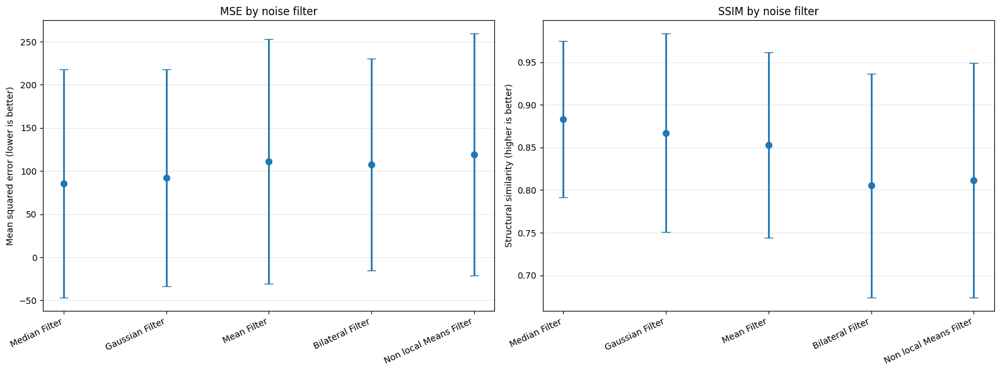

In [12]:
filter_names = list(filter_metrics)
x = np.arange(len(filter_names))
means = {metric: [filter_metrics[name][metric].mean() for name in filter_names]
         for metric in ("mse", "ssim")}
stds = {metric: [filter_metrics[name][metric].std() for name in filter_names]
        for metric in ("mse", "ssim")}

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for axis, metric, title, ylabel in zip(
    axes,
    ("mse", "ssim"),
    ("MSE by noise filter", "SSIM by noise filter"),
    ("Mean squared error (lower is better)", "Structural similarity (higher is better)"),
):
    axis.errorbar(
        x, means[metric], yerr=stds[metric], fmt="o", capsize=5,
        linewidth=2, markersize=7,
    )
    axis.set_xticks(x, filter_names, rotation=25, ha="right")
    axis.set_title(title)
    axis.set_ylabel(ylabel)
    axis.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

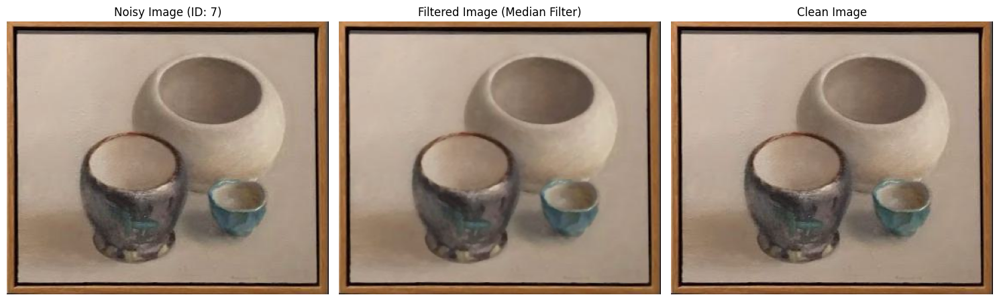

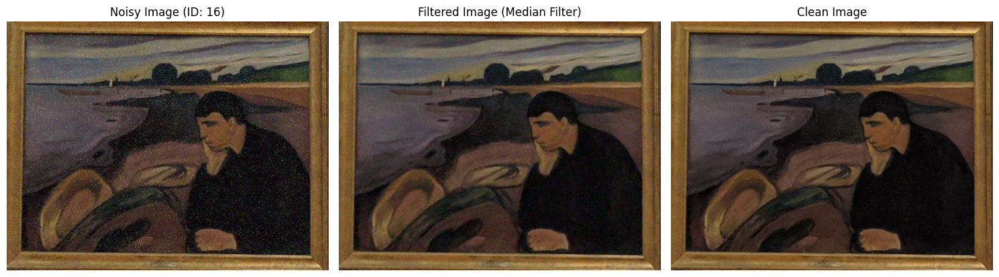

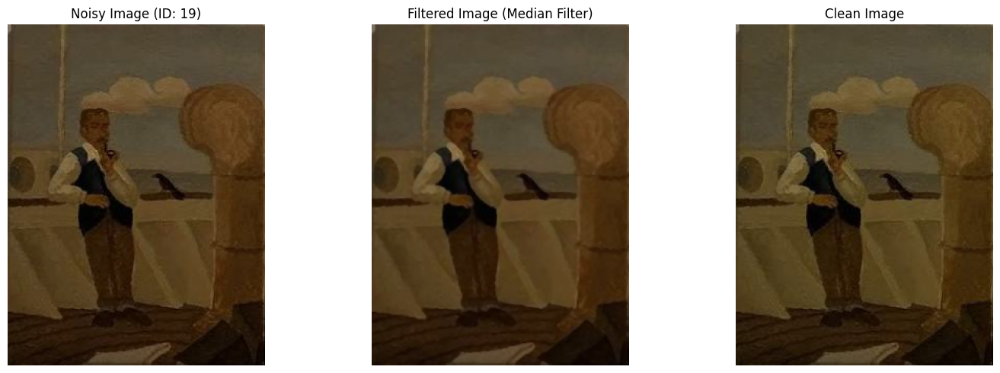

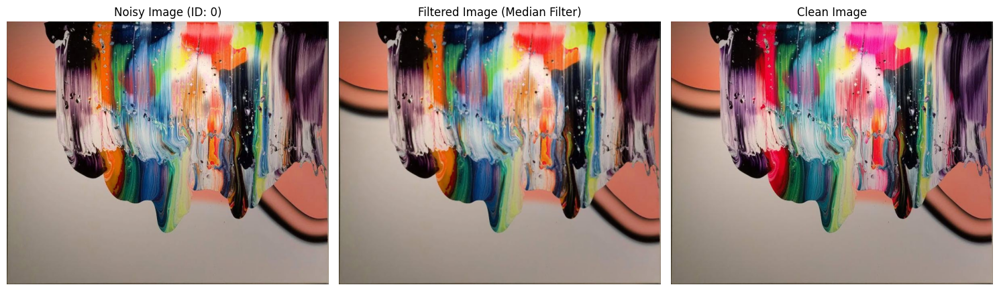

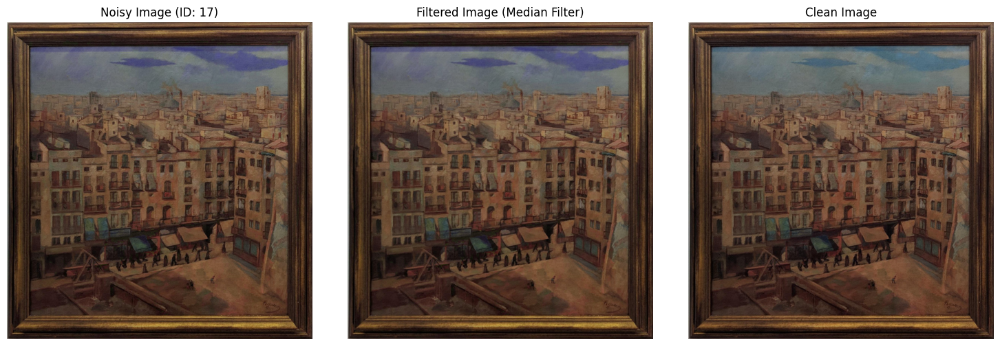

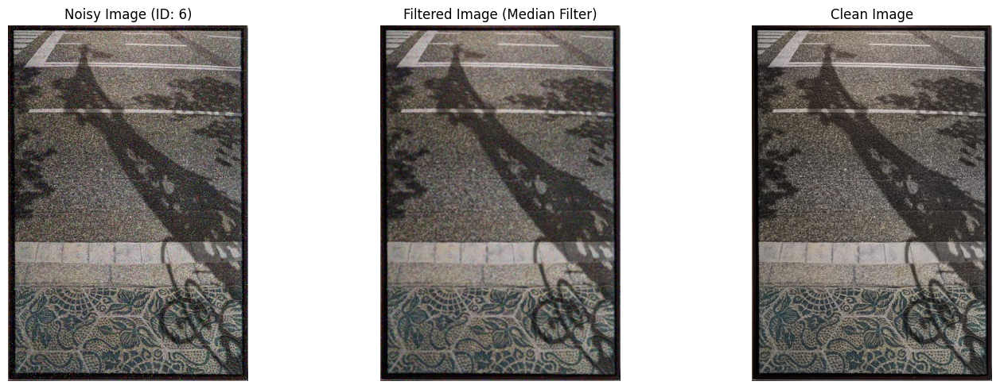

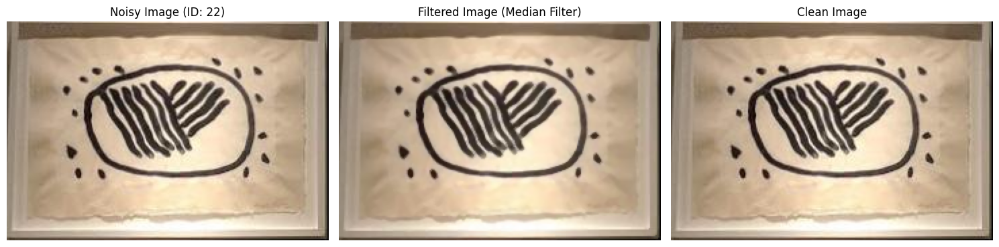

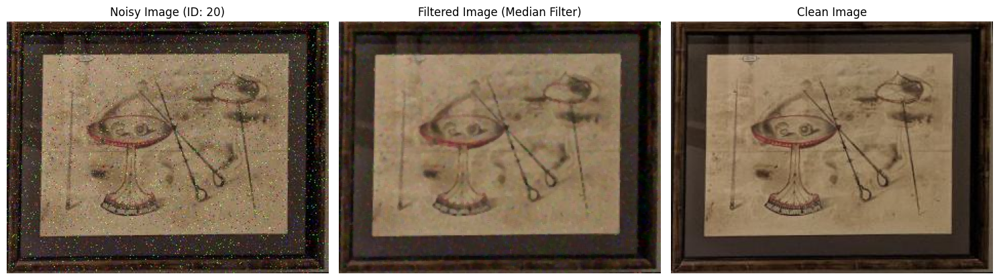

In [13]:
# Display the original noisy image, the filtered image, and the clean image for comparison for a random sample of images
n_images = 8

for i in range(n_images):
    random_index = random.randint(0, len(train_dataset.paths) - 1)
    image_path = train_dataset.paths[random_index]
    image_id_value = train_dataset.ids[random_index]

    # Load images
    noisy_image = read_rgb(image_path)
    clean_image = read_rgb(non_augmented_data.paths[random_index])
    filtered_image = cv2.medianBlur(noisy_image, 3)

    # Display images
    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1)
    plt.imshow(noisy_image)
    plt.title(f"Noisy Image (ID: {image_id_value})")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(filtered_image)
    plt.title("Filtered Image (Median Filter)")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(clean_image)
    plt.title("Clean Image")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

## Task 2 - Texture descriptors (QSD1-W3)

We implement two texture descriptors, **LBP** and **DCT**, and evaluate retrieval on QSD1-W3 using **only texture** (grayscale, no colour). Both are computed per block and concatenated, as in the colour block histograms. The queries are filtered with the median filter from Task 1 before computing the descriptors, because some of them are noisy.

In [14]:
import pandas as pd

db_dataset = load_image_dataset(f"{DATA_DIR}/BBDD")
query_dataset = train_dataset            # QSD1-W3: noisy / colour-changed queries
read = lambda p: cv2.imread(p.as_posix())
db_imgs = [read(p) for p in db_dataset.paths]
q_imgs  = [read(p) for p in query_dataset.paths]
db_ids = db_dataset.ids
print(len(db_imgs), len(q_imgs), len(ground_truth))     # expect 287 30 30

287 30 30


In [15]:
def to_gray(img_bgr):
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

def preprocess(img_bgr, denoise=True):
    return cv2.medianBlur(img_bgr, 3) if denoise else img_bgr

def hellinger(q, D):
    return np.sqrt(((np.sqrt(q) - np.sqrt(D)) ** 2).sum(axis=1))
def chi2(q, D, eps=1e-10):
    return 0.5 * (((q - D) ** 2) / (q + D + eps)).sum(axis=1)
def l1(q, D):
    return np.abs(q - D).sum(axis=1)
def l2(q, D):
    return np.sqrt(((q - D) ** 2).sum(axis=1))

def map_at_k(results, gt, k):
    aps = []
    for res, rel in zip(results, gt):
        ap, hits = 0.0, 0
        for r, img_id in enumerate(res[:k], start=1):
            if img_id in rel:
                hits += 1
                ap += hits / r
        aps.append(ap / min(len(rel), k))
    return float(np.mean(aps))

def evaluate(desc_fn, distances, db_imgs, q_imgs, db_ids, gt,
             denoise_queries=True, denoise_db=False, size=None):
    """Descriptors -> distances -> mAP@1 / mAP@5.
    denoise_queries / denoise_db: apply the median filter to queries / database images.
    size: if given, resize every image to size x size before the descriptor."""
    def prep(im, denoise):
        im = preprocess(im, denoise)
        return cv2.resize(im, (size, size), interpolation=cv2.INTER_AREA) if size else im
    D = np.array([desc_fn(to_gray(prep(im, denoise_db))) for im in db_imgs])
    Q = np.array([desc_fn(to_gray(prep(im, denoise_queries))) for im in q_imgs])
    out = {}
    for name, dist in distances.items():
        res = [[int(db_ids[i]) for i in np.argsort(dist(q, D), kind="stable")[:10]] for q in Q]
        out[name] = (map_at_k(res, gt, 1), map_at_k(res, gt, 5), res)
    return out

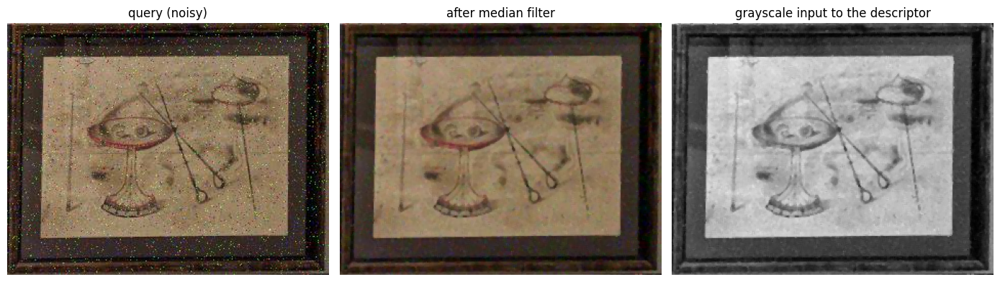

In [16]:
i = 20                                    # the noisy example you analysed in Task 1
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].imshow(cv2.cvtColor(q_imgs[i], cv2.COLOR_BGR2RGB)); ax[0].set_title("query (noisy)")
ax[1].imshow(cv2.cvtColor(preprocess(q_imgs[i]), cv2.COLOR_BGR2RGB)); ax[1].set_title("after median filter")
ax[2].imshow(to_gray(preprocess(q_imgs[i])), cmap="gray"); ax[2].set_title("grayscale input to the descriptor")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

### DCT descriptor
Each block is resized to a fixed size (16×16), transformed with the 2D DCT (`cv2.dct`) and read in zig-zag order, from low to high frequency. We keep the first N coefficients, skipping the first one (DC), which is the mean brightness and not texture. The coefficients of all blocks are concatenated and the vector is L2-normalised.

In [17]:
def zigzag_indices(n):
    idx = [(i, j) for i in range(n) for j in range(n)]
    return sorted(idx, key=lambda p: (p[0] + p[1], p[1] if (p[0] + p[1]) % 2 == 0 else p[0]))

_ZZ = {}
def dct_descriptor(gray, grid=8, block_size=16, n_coefs=5, skip_dc=True):
    if block_size not in _ZZ:
        _ZZ[block_size] = zigzag_indices(block_size)
    start = 1 if skip_dc else 0
    zz = _ZZ[block_size][start:start + n_coefs]
    h, w = gray.shape
    ys = np.linspace(0, h, grid + 1, dtype=int); xs = np.linspace(0, w, grid + 1, dtype=int)
    feats = []
    for i in range(grid):
        for j in range(grid):
            blk = gray[ys[i]:ys[i+1], xs[j]:xs[j+1]]
            blk = cv2.resize(blk, (block_size, block_size), interpolation=cv2.INTER_AREA).astype(np.float32)
            c = cv2.dct(blk)
            feats.append([c[a, b] for a, b in zz])
    v = np.asarray(feats, np.float32).ravel()
    return v / (np.linalg.norm(v) + 1e-12)

print(dct_descriptor(to_gray(db_imgs[0]), 8, 16, 5).shape)      # 8x8 blocks x 5 coefficients = (320,)

(320,)


In [18]:
dists_vec = {"l2": l2, "l1": l1}
dct_rows = []
for grid in (4, 8, 12):
    for n_coefs in (5, 10, 20):
        out = evaluate(lambda g: dct_descriptor(g, grid, 16, n_coefs), dists_vec, db_imgs, q_imgs, db_ids, ground_truth)
        for dname, (m1, m5, _) in out.items():
            dct_rows.append((grid, n_coefs, dname, m1, m5))
            print(f"grid {grid:>2}  coefs {n_coefs:>2}  {dname:<7} mAP@1 {m1:.3f}  mAP@5 {m5:.3f}")

df = pd.DataFrame(dct_rows, columns=["grid", "coefs", "dist", "mAP@1", "mAP@5"])
display(df.pivot_table(index=["grid", "dist"], columns="coefs", values="mAP@1").round(3))

grid  4  coefs  5  l2      mAP@1 0.933  mAP@5 0.933
grid  4  coefs  5  l1      mAP@1 0.933  mAP@5 0.944
grid  4  coefs 10  l2      mAP@1 0.933  mAP@5 0.951
grid  4  coefs 10  l1      mAP@1 0.967  mAP@5 0.983
grid  4  coefs 20  l2      mAP@1 0.967  mAP@5 0.975
grid  4  coefs 20  l1      mAP@1 1.000  mAP@5 1.000
grid  8  coefs  5  l2      mAP@1 0.967  mAP@5 0.967
grid  8  coefs  5  l1      mAP@1 1.000  mAP@5 1.000
grid  8  coefs 10  l2      mAP@1 0.933  mAP@5 0.967
grid  8  coefs 10  l1      mAP@1 0.967  mAP@5 0.983
grid  8  coefs 20  l2      mAP@1 0.933  mAP@5 0.961
grid  8  coefs 20  l1      mAP@1 0.967  mAP@5 0.983
grid 12  coefs  5  l2      mAP@1 0.967  mAP@5 0.983
grid 12  coefs  5  l1      mAP@1 0.967  mAP@5 0.983
grid 12  coefs 10  l2      mAP@1 0.867  mAP@5 0.933
grid 12  coefs 10  l1      mAP@1 0.900  mAP@5 0.950
grid 12  coefs 20  l2      mAP@1 0.900  mAP@5 0.950
grid 12  coefs 20  l1      mAP@1 0.867  mAP@5 0.933


coefs         5      10     20
grid dist                     
4    l1    0.933  0.967  1.000
     l2    0.933  0.933  0.967
8    l1    1.000  0.967  0.967
     l2    0.967  0.933  0.933
12   l1    0.967  0.900  0.867
     l2    0.967  0.867  0.900

### LBP (Local Binary Pattern)
For every pixel we compare it with its 8 neighbours: each neighbour that is greater than or equal to the centre gives a 1, otherwise a 0. The 8 bits form a number from 0 to 255 (the pixel's local pattern). We use scikit-image's `local_binary_pattern` to get the codes, split the image into N×N blocks, take the normalised histogram of the 256 codes in each block, and concatenate them. The multiscale version uses several neighbourhoods (P points at radius R) with the uniform-pattern histogram (P+2 bins).

In [19]:
from skimage.feature import local_binary_pattern

def block_hist(code_img, grid, n_bins):
    h, w = code_img.shape
    ys = np.linspace(0, h, grid + 1, dtype=int); xs = np.linspace(0, w, grid + 1, dtype=int)
    out = []
    for i in range(grid):
        for j in range(grid):
            blk = code_img[ys[i]:ys[i+1], xs[j]:xs[j+1]]
            hist = np.bincount(blk.ravel(), minlength=n_bins).astype(np.float32)
            out.append(hist / max(hist.sum(), 1e-12))
    return np.concatenate(out) / grid**2

def lbp_descriptor(gray, grid=4, scales=((8, 1.0),), uniform=False):
    parts = []
    for P, R in scales:
        method = "default" if ((P, R) == (8, 1.0) and not uniform) else "uniform"
        codes = local_binary_pattern(gray, P, R, method=method).astype(np.int32)
        n_bins = 256 if method == "default" else P + 2
        parts.append(block_hist(codes, grid, n_bins))
    d = np.concatenate(parts)
    return d / d.sum()

print(lbp_descriptor(to_gray(db_imgs[0]), grid=4).shape)      # (4096,) = 4x4 blocks x 256 bins

(4096,)


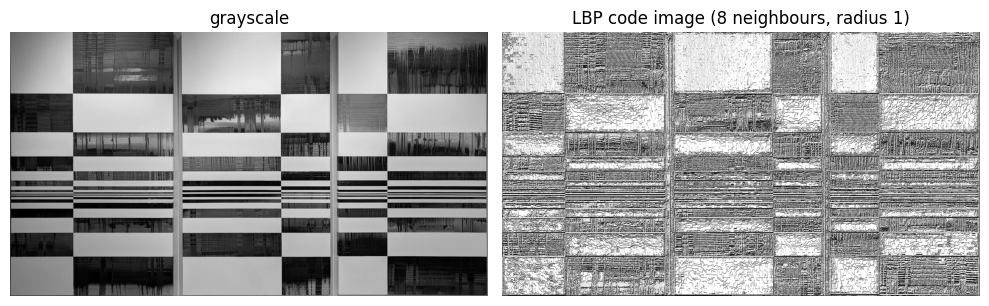

In [20]:
g = to_gray(db_imgs[0])
codes = local_binary_pattern(g, 8, 1.0, method="default")
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(g, cmap="gray"); ax[0].set_title("grayscale")
ax[1].imshow(codes, cmap="gray"); ax[1].set_title("LBP code image (8 neighbours, radius 1)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

#### First attempt: same pipeline as DCT
We first evaluate LBP exactly as DCT: queries filtered with the median filter, database images untouched, original image size.

In [21]:
dists_hist = {"hellinger": hellinger, "chi2": chi2, "l1": l1}
lbp_rows = []
for grid in (1, 2, 4, 8):
    out = evaluate(lambda g: lbp_descriptor(g, grid), dists_hist, db_imgs, q_imgs, db_ids, ground_truth)
    for dname, (m1, m5, _) in out.items():
        lbp_rows.append((f"8,1 grid {grid}", dname, m1, m5))
        print(f"LBP 8,1     grid {grid}  {dname:<10} mAP@1 {m1:.3f}  mAP@5 {m5:.3f}")

multi = ((8, 1.0), (12, 2.5), (16, 4.0))
for grid in (2, 4):
    out = evaluate(lambda g: lbp_descriptor(g, grid, multi), dists_hist, db_imgs, q_imgs, db_ids, ground_truth)
    for dname, (m1, m5, _) in out.items():
        lbp_rows.append((f"multiscale grid {grid}", dname, m1, m5))
        print(f"LBP multi   grid {grid}  {dname:<10} mAP@1 {m1:.3f}  mAP@5 {m5:.3f}")

LBP 8,1     grid 1  hellinger  mAP@1 0.000  mAP@5 0.000
LBP 8,1     grid 1  chi2       mAP@1 0.000  mAP@5 0.000
LBP 8,1     grid 1  l1         mAP@1 0.000  mAP@5 0.000
LBP 8,1     grid 2  hellinger  mAP@1 0.000  mAP@5 0.018
LBP 8,1     grid 2  chi2       mAP@1 0.000  mAP@5 0.019
LBP 8,1     grid 2  l1         mAP@1 0.033  mAP@5 0.047
LBP 8,1     grid 4  hellinger  mAP@1 0.100  mAP@5 0.125
LBP 8,1     grid 4  chi2       mAP@1 0.100  mAP@5 0.128
LBP 8,1     grid 4  l1         mAP@1 0.133  mAP@5 0.142
LBP 8,1     grid 8  hellinger  mAP@1 0.167  mAP@5 0.189
LBP 8,1     grid 8  chi2       mAP@1 0.200  mAP@5 0.218
LBP 8,1     grid 8  l1         mAP@1 0.200  mAP@5 0.230
LBP multi   grid 2  hellinger  mAP@1 0.000  mAP@5 0.000
LBP multi   grid 2  chi2       mAP@1 0.000  mAP@5 0.000
LBP multi   grid 2  l1         mAP@1 0.000  mAP@5 0.000
LBP multi   grid 4  hellinger  mAP@1 0.000  mAP@5 0.047
LBP multi   grid 4  chi2       mAP@1 0.000  mAP@5 0.054
LBP multi   grid 4  l1         mAP@1 0.000  mAP@

**Result of the first attempt: very poor.** With the 8-neighbour LBP, mAP@1 was between 0.000 and 0.200 (a global histogram gave 0.000, which is chance level among 287 paintings), and the multiscale version was even worse (0.000 mAP@1). The same pipeline gave 0.97 with DCT, so we looked for the cause. LBP compares each pixel with its neighbours, so it describes the finest grain of the photo. A possible reason is that the queries (filtered, with different sizes) and the database images (unfiltered) do not have the same fine texture, so their LBP histograms are not comparable. We test this next.

In [22]:
# Sanity check: a database image used as its own query must be retrieved first
out = evaluate(lambda g: lbp_descriptor(g, 4), {"l1": l1}, db_imgs, db_imgs[:30], db_ids,
               [[int(i)] for i in db_ids[:30]], denoise_queries=False)
print("database image used as query:", out["l1"][:2])      # expect 1.000 1.000

database image used as query: (1.0, 1.0)


In [23]:
for size in (None, 256):
    for dq, dd, label in [(False, False, "no filter"), (True, False, "filter queries only"), (True, True, "filter queries and database")]:
        for grid in (4, 8):
            out = evaluate(lambda g: lbp_descriptor(g, grid), {"l1": l1}, db_imgs, q_imgs, db_ids, ground_truth,
                           denoise_queries=dq, denoise_db=dd, size=size)
            m1, m5, _ = out["l1"]
            print(f"size {str(size):<5} {label:<28} grid {grid}  mAP@1 {m1:.3f}  mAP@5 {m5:.3f}")

size None  no filter                    grid 4  mAP@1 0.433  mAP@5 0.461
size None  no filter                    grid 8  mAP@1 0.600  mAP@5 0.623
size None  filter queries only          grid 4  mAP@1 0.133  mAP@5 0.142
size None  filter queries only          grid 8  mAP@1 0.200  mAP@5 0.230
size None  filter queries and database  grid 4  mAP@1 0.600  mAP@5 0.633
size None  filter queries and database  grid 8  mAP@1 0.767  mAP@5 0.775
size 256   no filter                    grid 4  mAP@1 0.733  mAP@5 0.789
size 256   no filter                    grid 8  mAP@1 0.867  mAP@5 0.867
size 256   filter queries only          grid 4  mAP@1 0.600  mAP@5 0.639
size 256   filter queries only          grid 8  mAP@1 0.867  mAP@5 0.892
size 256   filter queries and database  grid 4  mAP@1 0.733  mAP@5 0.800
size 256   filter queries and database  grid 8  mAP@1 0.933  mAP@5 0.944


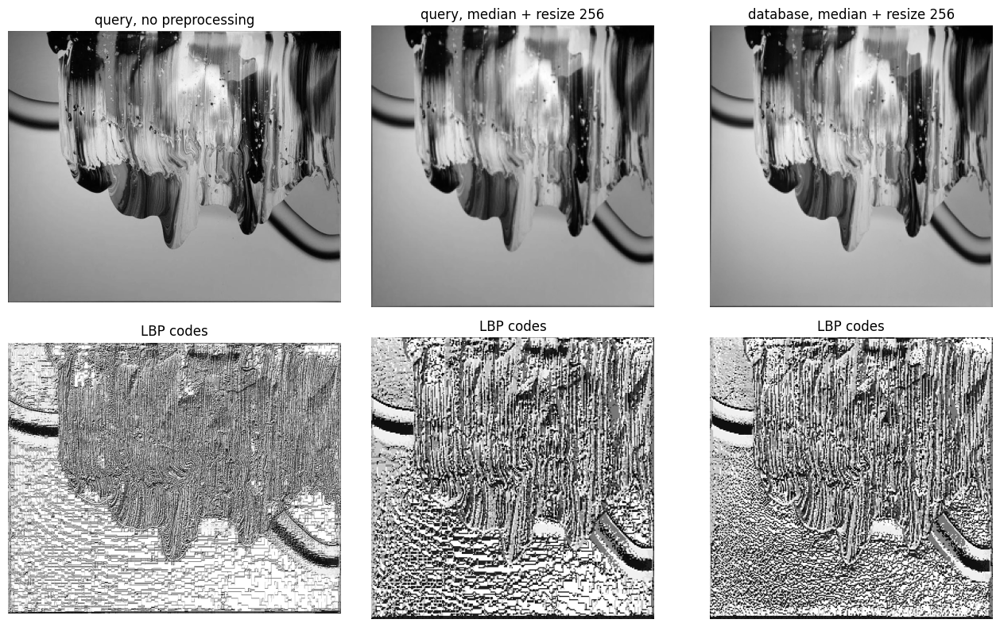

In [24]:
i = 0
gt_id = ground_truth[i][0]
db_img = db_imgs[list(db_ids).index(gt_id)]            # the correct painting

def lbp_img(im, den, size):
    im = preprocess(im, den)
    if size: im = cv2.resize(im, (size, size), interpolation=cv2.INTER_AREA)
    return local_binary_pattern(to_gray(im), 8, 1.0, method="default"), to_gray(im)

panels = [("query, no preprocessing", lbp_img(q_imgs[i], False, None)),
          ("query, median + resize 256", lbp_img(q_imgs[i], True, 256)),
          ("database, median + resize 256", lbp_img(db_img, True, 256))]
fig, ax = plt.subplots(2, 3, figsize=(13, 8))
for j, (title, (codes, g)) in enumerate(panels):
    ax[0, j].imshow(g, cmap="gray"); ax[0, j].set_title(title)
    ax[1, j].imshow(codes, cmap="gray"); ax[1, j].set_title("LBP codes")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

#### Effect of preprocessing on LBP (8 neighbours, radius 1, L1)
| pipeline | grid 4 mAP@1 / mAP@5 | grid 8 mAP@1 / mAP@5 |
|---|---|---|
| original size, filter queries only (first attempt) | 0.133 / 0.142 | 0.200 / 0.230 |
| original size, no filter | 0.433 / 0.461 | 0.600 / 0.623 |
| original size, filter queries and database | 0.600 / 0.633 | 0.767 / 0.775 |
| resize 256×256, filter queries only | 0.600 / 0.639 | 0.867 / 0.892 |
| resize 256×256, no filter | 0.733 / 0.789 | 0.867 / 0.867 |
| **resize 256×256, filter queries and database** | 0.733 / 0.800 | **0.933 / 0.944** |


In [25]:
dct_fn = lambda g: dct_descriptor(g, 8, 16, 5)
for size in (None, 256):
    for dq, dd, label in [(False, False, "no filter"), (True, False, "filter queries only"), (True, True, "filter queries and database")]:
        out = evaluate(dct_fn, {"l1": l1}, db_imgs, q_imgs, db_ids, ground_truth, denoise_queries=dq, denoise_db=dd, size=size)
        m1, m5, _ = out["l1"]
        print(f"DCT  size {str(size):<5} {label:<28} mAP@1 {m1:.3f}  mAP@5 {m5:.3f}")

DCT  size None  no filter                    mAP@1 1.000  mAP@5 1.000
DCT  size None  filter queries only          mAP@1 1.000  mAP@5 1.000
DCT  size None  filter queries and database  mAP@1 1.000  mAP@5 1.000
DCT  size 256   no filter                    mAP@1 1.000  mAP@5 1.000
DCT  size 256   filter queries only          mAP@1 1.000  mAP@5 1.000
DCT  size 256   filter queries and database  mAP@1 1.000  mAP@5 1.000


DCT is **not affected** by the preprocessing: it gives mAP@1 0.967 and mAP@5 0.983 in all six pipelines. Each block is resized to 16×16 with area averaging (which removes isolated noisy pixels and scale differences) and only low-frequency coefficients are kept. LBP reads individual pixels, so it needs both sides to be treated in the same way. For this reason, from now on both descriptors use the same pipeline: **resize to 256×256 and median filter on queries and database**.

#### LBP with the final pipeline
With the common preprocessing, we compare the LBP variants (256 codes, uniform, multiscale uniform), block grids from 6×6 to 16×16 and three distances.

In [26]:
variants = {
    "8,1 default (256 bins)": dict(scales=((8, 1.0),), uniform=False),
    "8,1 uniform (10 bins)":  dict(scales=((8, 1.0),), uniform=True),
    "multiscale uniform":     dict(scales=((8, 1.0), (12, 2.5), (16, 4.0)), uniform=True),
}
lbp_final_rows = []
for vname, kw in variants.items():
    for grid in (6, 8, 12, 16):
        out = evaluate(lambda g: lbp_descriptor(g, grid, **kw), dists_hist, db_imgs, q_imgs, db_ids, ground_truth,
                       denoise_queries=True, denoise_db=True, size=256)
        for dname, (m1, m5, _) in out.items():
            lbp_final_rows.append((vname, grid, dname, m1, m5))
            print(f"{vname:<24} grid {grid:>2}  {dname:<9} mAP@1 {m1:.3f}  mAP@5 {m5:.3f}")

8,1 default (256 bins)   grid  6  hellinger mAP@1 0.833  mAP@5 0.867
8,1 default (256 bins)   grid  6  chi2      mAP@1 0.833  mAP@5 0.875
8,1 default (256 bins)   grid  6  l1        mAP@1 0.833  mAP@5 0.883
8,1 default (256 bins)   grid  8  hellinger mAP@1 0.900  mAP@5 0.917
8,1 default (256 bins)   grid  8  chi2      mAP@1 0.900  mAP@5 0.917
8,1 default (256 bins)   grid  8  l1        mAP@1 0.933  mAP@5 0.944
8,1 default (256 bins)   grid 12  hellinger mAP@1 0.933  mAP@5 0.961
8,1 default (256 bins)   grid 12  chi2      mAP@1 0.933  mAP@5 0.961
8,1 default (256 bins)   grid 12  l1        mAP@1 0.967  mAP@5 0.973
8,1 default (256 bins)   grid 16  hellinger mAP@1 1.000  mAP@5 1.000
8,1 default (256 bins)   grid 16  chi2      mAP@1 1.000  mAP@5 1.000
8,1 default (256 bins)   grid 16  l1        mAP@1 1.000  mAP@5 1.000
8,1 uniform (10 bins)    grid  6  hellinger mAP@1 0.467  mAP@5 0.494
8,1 uniform (10 bins)    grid  6  chi2      mAP@1 0.467  mAP@5 0.500
8,1 uniform (10 bins)    grid  6  

In [27]:
for grid in (16, 20, 24):
    out = evaluate(lambda g: lbp_descriptor(g, grid), dists_hist, db_imgs, q_imgs, db_ids, ground_truth,
                   denoise_queries=True, denoise_db=True, size=256)
    for dname, (m1, m5, _) in out.items():
        print(f"grid {grid}  {dname:<9} mAP@1 {m1:.3f}  mAP@5 {m5:.3f}")

grid 16  hellinger mAP@1 1.000  mAP@5 1.000
grid 16  chi2      mAP@1 1.000  mAP@5 1.000
grid 16  l1        mAP@1 1.000  mAP@5 1.000
grid 20  hellinger mAP@1 1.000  mAP@5 1.000
grid 20  chi2      mAP@1 1.000  mAP@5 1.000
grid 20  l1        mAP@1 1.000  mAP@5 1.000
grid 24  hellinger mAP@1 1.000  mAP@5 1.000
grid 24  chi2      mAP@1 1.000  mAP@5 1.000
grid 24  l1        mAP@1 1.000  mAP@5 1.000


#### Final LBP
Chosen setting: LBP with 8 neighbours and radius 1 (256 codes), 16×16 blocks of the 256×256 image, L1 distance. mAP@1 1.000 / mAP@5 1.000 on QSD1-W3, texture only.
Results increase with the number of blocks and are identical for Hellinger, χ² and L1 at 16×16. Grids 16, 20 and 24 all give 1.000 / 1.000 with the three distances, so 16×16 sits on a stable plateau, not on an isolated peak. The uniform (10 bins) and multiscale variants were worse (0.733 and 0.867 mAP@1 at best). The setting was chosen on the 30 development queries (one query = 0.033), so the real score on unseen queries may be slightly lower.

#### DCT vs LBP (texture only, QSD1-W3, 30 queries)


In [28]:
import pandas as pd

rows = []
for name, fn, desc_len in [("DCT", lambda g: dct_descriptor(g, 8, 16, 10), 640),
                           ("LBP", lambda g: lbp_descriptor(g, 16), 65536)]:
    out = evaluate(fn, {"l1": l1}, db_imgs, q_imgs, db_ids, ground_truth,
                   denoise_queries=True, denoise_db=True, size=256)
    m1, m5, _ = out["l1"]
    out_bad = evaluate(fn, {"l1": l1}, db_imgs, q_imgs, db_ids, ground_truth)       # queries filtered only, original size
    rows.append((name, desc_len, out_bad["l1"][0], m1, m5))

table = pd.DataFrame(rows, columns=["descriptor", "values per image", "mAP@1 (queries filtered only)",
                                    "mAP@1 (same pipeline both sides)", "mAP@5 (same pipeline both sides)"])
display(table.round(3))


,descriptor,values per image,mAP@1 (queries filtered only),mAP@1 (same pipeline both sides),mAP@5 (same pipeline both sides)
0,DCT,640,0.967,0.967,0.983
1,LBP,65536,0.300,1.000,1.000


## Task 3 - Painting detection and background removal (QSD2-W3)

QSD2-W3 contains non-cropped photographs with one or two paintings. The goal is to detect every painting, remove the surrounding wall/background, and create one binary foreground mask per query image. A two-painting query still has one combined mask containing both foreground regions.

We reuse the Week 2 colour-based background model and extend it for multiple paintings. Nearby foreground fragments are merged, at most two painting regions are retained, and a rectangular painting prior is used to fill incomplete masks. Ground-truth PNG masks are used only to evaluate the predictions.

In [31]:
import sys

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.segmentation import foreground_mask

qsd2_w3_paths = tuple(sorted((DATA_DIR / "qsd2_w3").glob("*.jpg")))
qsd2_w3_dataset = ImageDataset(
    paths=qsd2_w3_paths,
    ids=np.asarray(
        [int(path.stem.rsplit("_", 1)[-1]) for path in qsd2_w3_paths],
        dtype=int,
    ),
)
qsd2_w3_imgs = [read(path) for path in qsd2_w3_dataset.paths]

with (DATA_DIR / "qsd2_w3" / "gt_corresps.pkl").open("rb") as stream:
    qsd2_w3_gt = [
        [int(value) for value in row]
        for row in pickle.load(stream)
    ]

reference_masks = []
for path in qsd2_w3_dataset.paths:
    reference = cv2.imread(str(path.with_suffix(".png")), cv2.IMREAD_GRAYSCALE)
    if reference is None:
        raise FileNotFoundError(f"Missing ground-truth mask for {path.name}")
    reference_masks.append(reference > 127)

assert len(qsd2_w3_imgs) == len(qsd2_w3_gt)
assert len(qsd2_w3_imgs) == len(reference_masks)
print("QSD2-W3 queries:", len(qsd2_w3_imgs))
print("One-painting queries:", sum(len(row) == 1 for row in qsd2_w3_gt))
print("Two-painting queries:", sum(len(row) == 2 for row in qsd2_w3_gt))


TypeError: unsupported operand type(s) for |: 'type' and 'type'

### Multi-painting foreground detection

The Week 2 method models background colour from strips along the image border. Pixels sufficiently different from that model become foreground. In Week 3 a single painting can appear as several disconnected fragments, so components whose bounding boxes overlap or are close are grouped before choosing the two largest painting candidates. The minimum-area rectangle of each group fills gaps while preserving rotation.

In [ ]:
def _boxes_are_near(box_a, box_b, gap):
    xa, ya, wa, ha = box_a
    xb, yb, wb, hb = box_b
    return not (
        xa + wa + gap < xb
        or xb + wb + gap < xa
        or ya + ha + gap < yb
        or yb + hb + gap < ya
    )


def detect_painting_mask(
    image,
    max_paintings=2,
    component_min_area=0.005,
    painting_min_area=0.02,
    merge_gap_fraction=0.04,
):
    """Predict one combined mask and up to two left-to-right regions."""
    raw_mask = foreground_mask(
        image, min_area=component_min_area, keep="all"
    )
    count, labels, stats, _ = cv2.connectedComponentsWithStats(
        raw_mask.astype(np.uint8), connectivity=8
    )

    image_area = raw_mask.size
    component_ids = [
        label
        for label in range(1, count)
        if stats[label, cv2.CC_STAT_AREA] >= component_min_area * image_area
    ]

    parent = {label: label for label in component_ids}

    def find(label):
        while parent[label] != label:
            parent[label] = parent[parent[label]]
            label = parent[label]
        return label

    def union(label_a, label_b):
        root_a, root_b = find(label_a), find(label_b)
        if root_a != root_b:
            parent[root_b] = root_a

    merge_gap = merge_gap_fraction * min(raw_mask.shape)
    for position, label_a in enumerate(component_ids):
        box_a = tuple(int(value) for value in stats[label_a, :4])
        for label_b in component_ids[position + 1:]:
            box_b = tuple(int(value) for value in stats[label_b, :4])
            if _boxes_are_near(box_a, box_b, merge_gap):
                union(label_a, label_b)

    groups = {}
    for label in component_ids:
        groups.setdefault(find(label), []).append(label)

    regions = []
    for group_labels in groups.values():
        component_mask = np.isin(labels, group_labels)
        component_area = int(component_mask.sum())
        if component_area < painting_min_area * image_area:
            continue

        rows, columns = np.where(component_mask)
        points = np.column_stack((columns, rows)).astype(np.float32)
        box = cv2.boxPoints(cv2.minAreaRect(points))
        regions.append({"area": component_area, "box": box})

    regions = sorted(
        regions, key=lambda region: region["area"], reverse=True
    )[:max_paintings]
    regions.sort(key=lambda region: float(region["box"][:, 0].mean()))

    combined_mask = np.zeros(raw_mask.shape, dtype=np.uint8)
    for region in regions:
        region_mask = np.zeros(raw_mask.shape, dtype=np.uint8)
        polygon = np.round(region["box"]).astype(np.int32)
        cv2.fillConvexPoly(region_mask, polygon, 1)
        region["mask"] = region_mask.astype(bool)
        combined_mask |= region_mask

    return combined_mask.astype(bool), regions


In [ ]:
detections = [detect_painting_mask(image) for image in qsd2_w3_imgs]
predicted_masks = [mask for mask, _ in detections]
all_regions = [query_regions for _, query_regions in detections]
binary_masks = [mask.astype(np.uint8) * 255 for mask in predicted_masks]

print("Generated", len(binary_masks), "binary masks")
print("Mask values:", sorted(np.unique(binary_masks[0]).tolist()))


Generated 30 binary masks
Mask values: [0, 255]


### Mask and painting-count evaluation

Foreground is the positive class. Precision measures how much predicted foreground is truly painting, recall measures how much of the painting was retained, and F1 balances both. Macro scores average the 30 image-level scores; micro scores first combine all pixels. The expected painting count is read from the development correspondences only for evaluation and is never used by the detector.

In [ ]:
def mask_counts(reference, prediction):
    return {
        "tp": int(np.count_nonzero(reference & prediction)),
        "fp": int(np.count_nonzero(~reference & prediction)),
        "fn": int(np.count_nonzero(reference & ~prediction)),
        "tn": int(np.count_nonzero(~reference & ~prediction)),
    }


def segmentation_scores(counts):
    precision = counts["tp"] / max(counts["tp"] + counts["fp"], 1)
    recall = counts["tp"] / max(counts["tp"] + counts["fn"], 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)
    return precision, recall, f1


evaluation_rows = []
total_counts = {name: 0 for name in ("tp", "fp", "fn", "tn")}

for query_position, (reference, prediction, query_regions, correspondences) in enumerate(
    zip(
        reference_masks,
        predicted_masks,
        all_regions,
        qsd2_w3_gt,
    )
):
    counts = mask_counts(reference, prediction)
    precision, recall, f1 = segmentation_scores(counts)
    for name in total_counts:
        total_counts[name] += counts[name]
    evaluation_rows.append(
        {
            "query": int(qsd2_w3_dataset.ids[query_position]),
            "expected paintings": len(correspondences),
            "detected paintings": len(query_regions),
            "precision": precision,
            "recall": recall,
            "F1": f1,
        }
    )

evaluation = pd.DataFrame(evaluation_rows)
micro_precision, micro_recall, micro_f1 = segmentation_scores(total_counts)
evaluation_summary = pd.DataFrame(
    [
        {
            "averaging": "macro",
            "precision": evaluation["precision"].mean(),
            "recall": evaluation["recall"].mean(),
            "F1": evaluation["F1"].mean(),
            "painting-count accuracy": np.mean(
                evaluation["expected paintings"]
                == evaluation["detected paintings"]
            ),
        },
        {
            "averaging": "micro",
            "precision": micro_precision,
            "recall": micro_recall,
            "F1": micro_f1,
            "painting-count accuracy": np.nan,
        },
    ]
)

display(evaluation_summary.round(3))

count_errors = evaluation[
    evaluation["expected paintings"]
    != evaluation["detected paintings"]
]
if len(count_errors):
    print("Queries with an incorrect painting count:")
    display(count_errors.round(3))
else:
    print("The predicted painting count is correct for every development query.")


,averaging,precision,recall,F1,painting-count accuracy
0,macro,0.929,0.974,0.948,1.0
1,micro,0.958,0.952,0.955,NaN


The predicted painting count is correct for every development query.


In [ ]:
painting_count_accuracy = np.mean(
    evaluation["expected paintings"]
    == evaluation["detected paintings"]
)

display(evaluation_summary.drop(columns="painting-count accuracy"))
print(f"Painting-count accuracy: {painting_count_accuracy:.3f}")

,averaging,precision,recall,F1
0,macro,0.929451,0.973998,0.947519
1,micro,0.958323,0.952159,0.955231


Painting-count accuracy: 1.000


We correctly detected the number of paintings in every development image. It achieved a macro F1-score of 0.948 for background removal. The higher recall than precision indicates that the masks preserve almost all painting regions, while occasionally including some surrounding background

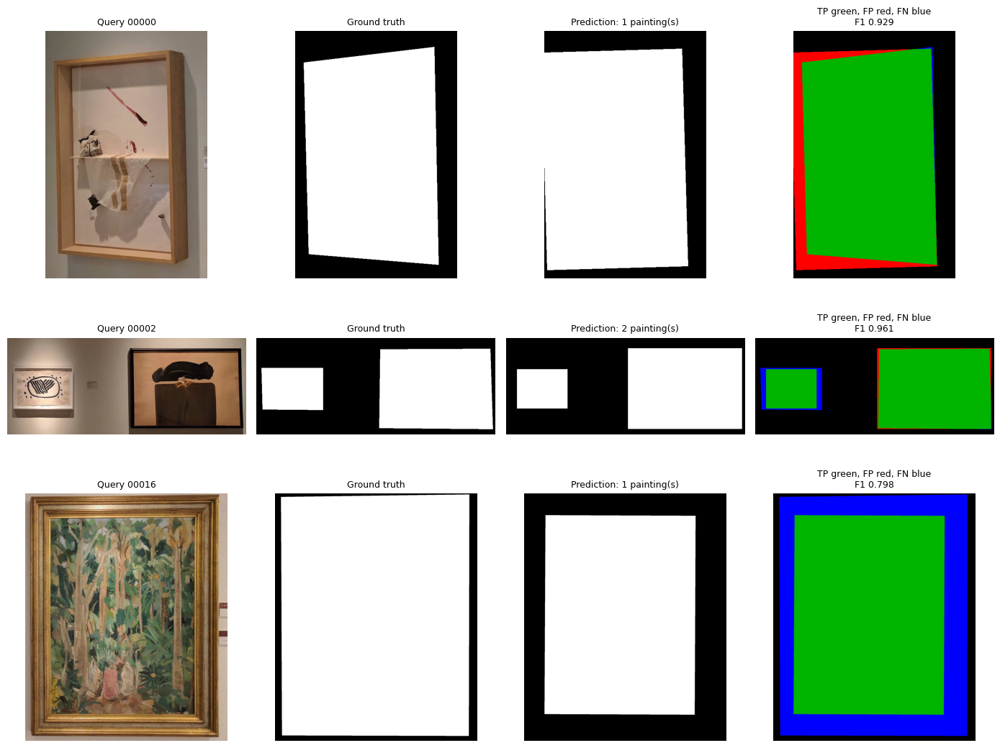

In [ ]:
def show_evaluation(indices):
    figure, axes = plt.subplots(
        len(indices), 4, figsize=(14, 3.5 * len(indices))
    )
    axes = np.atleast_2d(axes)

    for row, query_position in enumerate(indices):
        image = cv2.cvtColor(
            qsd2_w3_imgs[query_position],
            cv2.COLOR_BGR2RGB,
        )
        reference = reference_masks[query_position]
        prediction = predicted_masks[query_position]

        errors = np.zeros((*reference.shape, 3), dtype=np.uint8)
        errors[reference & prediction] = (0, 180, 0)    # true positives
        errors[~reference & prediction] = (255, 0, 0)  # false positives
        errors[reference & ~prediction] = (0, 0, 255)  # false negatives

        values = [image, reference, prediction, errors]
        titles = [
            f"Query {qsd2_w3_dataset.ids[query_position]:05d}",
            "Ground truth",
            f"Prediction: {len(all_regions[query_position])} painting(s)",
            (
                "TP green, FP red, FN blue\n"
                f"F1 {evaluation.iloc[query_position]['F1']:.3f}"
            ),
        ]

        for axis, value, title in zip(axes[row], values, titles):
            axis.imshow(value, cmap="gray" if value.ndim == 2 else None)
            axis.set_title(title, fontsize=9)
            axis.axis("off")

    plt.tight_layout()
    plt.show()


one_painting_example = next(
    index for index, matches in enumerate(qsd2_w3_gt)
    if len(matches) == 1
)

two_painting_example = next(
    index for index, matches in enumerate(qsd2_w3_gt)
    if len(matches) == 2
)

worst_mask_example = int(evaluation["F1"].idxmin())

evaluation_example_indices = list(
    dict.fromkeys([
        one_painting_example,
        two_painting_example,
        worst_mask_example,
    ])
)

show_evaluation(evaluation_example_indices)

### Background-removal examples

The following visualization applies the predicted mask to the query. Background pixels are set to white, while the detected painting pixels keep their original RGB values. The outlined image also makes the one- versus two-painting decision explicit.

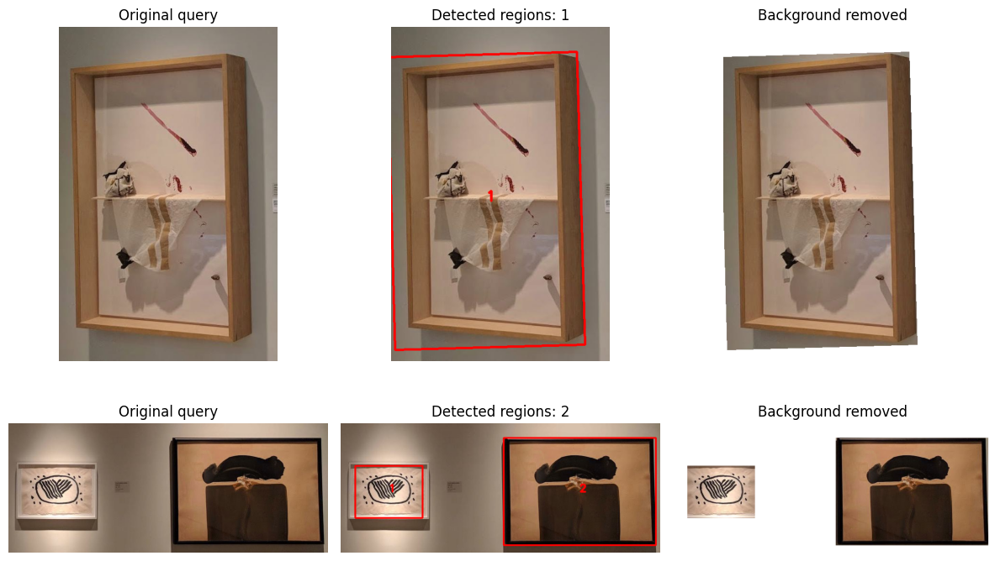

In [ ]:
def show_background_removal(indices):
    figure, axes = plt.subplots(len(indices), 3, figsize=(12, 4 * len(indices)))
    axes = np.atleast_2d(axes)

    for row, query_position in enumerate(indices):
        image_bgr = qsd2_w3_imgs[query_position]
        image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
        mask = predicted_masks[query_position]
        query_regions = all_regions[query_position]

        outlined = image_rgb.copy()
        for painting_position, region in enumerate(query_regions, start=1):
            polygon = np.round(region["box"]).astype(np.int32)
            cv2.polylines(outlined, [polygon], True, (255, 0, 0), 4)
            centre = np.round(region["box"].mean(axis=0)).astype(int)
            cv2.putText(
                outlined,
                str(painting_position),
                tuple(centre),
                cv2.FONT_HERSHEY_SIMPLEX,
                1.0,
                (255, 0, 0),
                3,
                cv2.LINE_AA,
            )

        foreground = image_rgb.copy()
        foreground[~mask] = 255

        axes[row, 0].imshow(image_rgb)
        axes[row, 0].set_title("Original query")
        axes[row, 1].imshow(outlined)
        axes[row, 1].set_title(f"Detected regions: {len(query_regions)}")
        axes[row, 2].imshow(foreground)
        axes[row, 2].set_title("Background removed")
        for axis in axes[row]:
            axis.axis("off")

    plt.tight_layout()
    plt.show()


show_background_removal([one_painting_example, two_painting_example])


### Task 3 interpretation

The macro and micro mask scores quantify background removal, while painting-count accuracy verifies that one- and two-painting queries are separated correctly. Use the error visualizations to determine whether remaining failures come from wall pixels included as foreground (red) or painting pixels removed as background (blue). The predicted masks in `binary_masks` contain only 0 and 255 and are ready for retrieval and submission.

## Task 4 - Multi-painting retrieval (QSD2-W3)

Each detected painting is treated as an independent query. We remove the background with the predicted region, rectify the rotated painting to an axis-aligned crop, and apply the best Task 2 texture pipeline: median filtering, resize to 256 x 256, LBP with a 16 x 16 grid, and L1 distance.

The result has three levels: `query -> painting -> top-10 BBDD identifiers`. Paintings within a query remain ordered from left to right.

In [ ]:
def order_box_points(points):
    points = np.asarray(points, dtype=np.float32)
    ordered = np.zeros((4, 2), dtype=np.float32)
    coordinate_sum = points.sum(axis=1)
    coordinate_difference = np.diff(points, axis=1).ravel()
    ordered[0] = points[np.argmin(coordinate_sum)]         # top-left
    ordered[1] = points[np.argmin(coordinate_difference)]  # top-right
    ordered[2] = points[np.argmax(coordinate_sum)]         # bottom-right
    ordered[3] = points[np.argmax(coordinate_difference)]  # bottom-left
    return ordered


def extract_painting(image, region):
    source = order_box_points(region["box"])
    top_left, top_right, bottom_right, bottom_left = source

    width = max(
        int(round(np.linalg.norm(top_right - top_left))),
        int(round(np.linalg.norm(bottom_right - bottom_left))),
        2,
    )
    height = max(
        int(round(np.linalg.norm(bottom_left - top_left))),
        int(round(np.linalg.norm(bottom_right - top_right))),
        2,
    )

    destination = np.array(
        [[0, 0], [width - 1, 0], [width - 1, height - 1], [0, height - 1]],
        dtype=np.float32,
    )

    foreground = image.copy()
    foreground[~region["mask"]] = 255
    transform = cv2.getPerspectiveTransform(source, destination)
    return cv2.warpPerspective(
        foreground,
        transform,
        (width, height),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=(255, 255, 255),
    )


query_paintings = [
    [extract_painting(image, region) for region in query_regions]
    for image, query_regions in zip(qsd2_w3_imgs, all_regions)
]

assert all(len(paintings) == len(query_regions) for paintings, query_regions in zip(query_paintings, all_regions))
print("Extracted paintings:", sum(map(len, query_paintings)))


Extracted paintings: 39


In [ ]:
def texture_input(image, size=256):
    filtered = preprocess(image, denoise=True)
    resized = cv2.resize(filtered, (size, size), interpolation=cv2.INTER_AREA)
    return to_gray(resized)


def texture_descriptor(image):
    return lbp_descriptor(texture_input(image), grid=16)


database_descriptors = np.vstack([
    texture_descriptor(image) for image in db_imgs
]).astype(np.float32)


def retrieve_painting(image, k=10):
    descriptor = texture_descriptor(image)
    distances = l1(descriptor, database_descriptors)
    ranking = np.argsort(distances, kind="stable")[:k]
    return [int(db_ids[index]) for index in ranking]


qsd2_w3_results = [
    [retrieve_painting(painting, k=10) for painting in paintings]
    for paintings in query_paintings
]

assert len(qsd2_w3_results) == len(qsd2_w3_imgs)
assert all(len(result) == len(paintings) for result, paintings in zip(qsd2_w3_results, query_paintings))
assert all(
    len(ranking) == 10 and all(isinstance(identifier, int) for identifier in ranking)
    for result in qsd2_w3_results
    for ranking in result
)

print("One-painting result example:", qsd2_w3_results[one_painting_example])
print("Two-painting result example:", qsd2_w3_results[two_painting_example])


One-painting result example: [[236, 229, 47, 114, 141, 38, 77, 258, 264, 207]]
Two-painting result example: [[280, 246, 185, 204, 211, 285, 212, 136, 249, 172], [285, 258, 207, 114, 189, 36, 47, 178, 238, 206]]


### Retrieval evaluation

The QSD2-W3 ground truth contains one database identifier per painting, in the same left-to-right order. We therefore evaluate every detected painting independently and also report the fraction of complete query images for which every painting is ranked first.

In [ ]:
painting_rankings = [
    ranking
    for query_result in qsd2_w3_results
    for ranking in query_result
]
painting_ground_truth = [
    [int(identifier)]
    for query_ground_truth in qsd2_w3_gt
    for identifier in query_ground_truth
]

assert len(painting_rankings) == len(painting_ground_truth)

complete_query_accuracy = np.mean([
    all(ranking[0] == identifier for ranking, identifier in zip(query_result, query_ground_truth))
    for query_result, query_ground_truth in zip(qsd2_w3_results, qsd2_w3_gt)
])

retrieval_summary = pd.DataFrame([
    {
        "descriptor": "LBP",
        "paintings": len(painting_rankings),
        "mAP@1": map_at_k(painting_rankings, painting_ground_truth, 1),
        "mAP@5": map_at_k(painting_rankings, painting_ground_truth, 5),
        "mAP@10": map_at_k(painting_rankings, painting_ground_truth, 10),
        "complete-query top-1 accuracy": complete_query_accuracy,
    }
])
display(retrieval_summary.round(3))


,paintings,mAP@1,mAP@5,mAP@10,complete-query top-1 accuracy
0,39,0.769,0.787,0.796,0.733


### Texture alternatives that improve QSD2-W3

The original LBP uses eight neighbours at radius 1. Increasing the radius captures texture over a wider neighbourhood and is less sensitive to isolated pixel changes.

In [ ]:
flat_query_paintings = [
    painting
    for paintings in query_paintings
    for painting in paintings
]


def rankings_to_queries(flat_rankings):
    nested = []
    position = 0
    for paintings in query_paintings:
        count = len(paintings)
        nested.append(flat_rankings[position:position + count])
        position += count
    assert position == len(flat_rankings)
    return nested


def rank_descriptor_matrices(query_matrix, database_matrix, distance_function):
    flat_rankings = [
        [int(db_ids[index]) for index in np.argsort(
            distance_function(descriptor, database_matrix),
            kind="stable",
        )[:10]]
        for descriptor in query_matrix
    ]
    return rankings_to_queries(flat_rankings)


def correspondence_metrics(results):
    rankings = [ranking for query_result in results for ranking in query_result]
    complete_query_accuracy = np.mean([
        all(ranking[0] == identifier for ranking, identifier in zip(query_result, query_ground_truth))
        for query_result, query_ground_truth in zip(results, qsd2_w3_gt)
    ])
    return {
        "paintings": len(rankings),
        "mAP@1": map_at_k(rankings, painting_ground_truth, 1),
        "mAP@5": map_at_k(rankings, painting_ground_truth, 5),
        "mAP@10": map_at_k(rankings, painting_ground_truth, 10),
        "complete-query top-1 accuracy": complete_query_accuracy,
    }


def lbp_radius_descriptor(image, grid, radius):
    gray = texture_input(image)
    codes = local_binary_pattern(
        gray, 8, radius, method="default"
    ).astype(np.int32)
    descriptor = block_hist(codes, grid, 256)
    return descriptor / (descriptor.sum() + 1e-12)


radius_configurations = {
    "LBP radius 2, grid 12, L1": (12, 2.0, l1),
    "LBP radius 2, grid 16, Hellinger": (16, 2.0, hellinger),
}
radius_results = {}

for name, (grid, radius, distance_function) in radius_configurations.items():
    database_matrix = np.vstack([
        lbp_radius_descriptor(image, grid, radius) for image in db_imgs
    ]).astype(np.float32)
    query_matrix = np.vstack([
        lbp_radius_descriptor(image, grid, radius) for image in flat_query_paintings
    ]).astype(np.float32)
    radius_results[name] = rank_descriptor_matrices(
        query_matrix, database_matrix, distance_function
    )

radius_comparison = pd.DataFrame([
    {"method": "LBP radius 1, grid 16, L1", **correspondence_metrics(qsd2_w3_results)},
    *[
        {"method": name, **correspondence_metrics(results)}
        for name, results in radius_results.items()
    ],
])
display(radius_comparison.round(3))


,method,paintings,mAP@1,mAP@5,mAP@10,complete-query top-1 accuracy
0,"LBP radius 1, grid 16, L1",39,0.769,0.787,0.796,0.733
1,"LBP radius 2, grid 12, L1",39,0.846,0.846,0.849,0.833
2,"LBP radius 2, grid 16, Hellinger",39,0.846,0.868,0.876,0.800


### Haar wavelet texture descriptor

A two-level 2D Haar transform separates each block into horizontal, vertical and diagonal detail bands at two scales. For every band we record the mean absolute response, standard deviation, root-mean-square energy and 75th percentile. The statistics from an 8 x 8 spatial grid are concatenated and compared with L1 distance.

In [ ]:
def haar_step(values):
    height = values.shape[0] // 2 * 2
    width = values.shape[1] // 2 * 2
    values = values[:height, :width]

    low_rows = (values[0::2] + values[1::2]) / np.sqrt(2.0)
    high_rows = (values[0::2] - values[1::2]) / np.sqrt(2.0)
    approximation = (low_rows[:, 0::2] + low_rows[:, 1::2]) / np.sqrt(2.0)
    horizontal = (low_rows[:, 0::2] - low_rows[:, 1::2]) / np.sqrt(2.0)
    vertical = (high_rows[:, 0::2] + high_rows[:, 1::2]) / np.sqrt(2.0)
    diagonal = (high_rows[:, 0::2] - high_rows[:, 1::2]) / np.sqrt(2.0)
    return approximation, (horizontal, vertical, diagonal)


def haar_descriptor(image, grid=8, levels=2):
    gray = texture_input(image).astype(np.float32) / 255.0
    height, width = gray.shape
    y_edges = np.linspace(0, height, grid + 1, dtype=int)
    x_edges = np.linspace(0, width, grid + 1, dtype=int)
    features = []

    for row in range(grid):
        for column in range(grid):
            approximation = gray[
                y_edges[row]:y_edges[row + 1],
                x_edges[column]:x_edges[column + 1],
            ]
            detail_bands = []
            for _ in range(levels):
                approximation, details = haar_step(approximation)
                detail_bands.extend(details)

            for band in detail_bands:
                magnitude = np.abs(band)
                features.extend([
                    magnitude.mean(),
                    magnitude.std(),
                    np.sqrt(np.mean(magnitude ** 2)),
                    np.percentile(magnitude, 75),
                ])

    descriptor = np.asarray(features, dtype=np.float32)
    return descriptor / (np.linalg.norm(descriptor) + 1e-12)


haar_database_descriptors = np.vstack([
    haar_descriptor(image) for image in db_imgs
]).astype(np.float32)
haar_query_descriptors = np.vstack([
    haar_descriptor(image) for image in flat_query_paintings
]).astype(np.float32)
haar_results = rank_descriptor_matrices(
    haar_query_descriptors, haar_database_descriptors, l1
)
display(pd.DataFrame([
    {"method": "Haar, two levels, grid 8, L1", **correspondence_metrics(haar_results)}
]).round(3))


,method,paintings,mAP@1,mAP@5,mAP@10,complete-query top-1 accuracy
0,"Haar, two levels, grid 8, L1",39,0.821,0.829,0.829,0.8


### Normalized LBP and DCT distance fusion

LBP and DCT make different retrieval errors. For each query painting, both distance vectors are min-max normalized across the database and combined as `0.8 x LBP + 0.2 x DCT`. The DCT branch uses the best compact Task 2 configuration: an 8 x 8 grid and five low-frequency AC coefficients per block.

In [ ]:
baseline_lbp_queries = np.vstack([
    texture_descriptor(image) for image in flat_query_paintings
]).astype(np.float32)
lbp_distance_matrix = np.vstack([
    l1(descriptor, database_descriptors)
    for descriptor in baseline_lbp_queries
])


def compact_dct_descriptor(image):
    return dct_descriptor(
        texture_input(image),
        grid=8,
        block_size=16,
        n_coefs=5,
    )


dct_database_descriptors = np.vstack([
    compact_dct_descriptor(image) for image in db_imgs
]).astype(np.float32)
dct_query_descriptors = np.vstack([
    compact_dct_descriptor(image) for image in flat_query_paintings
]).astype(np.float32)
dct_distance_matrix = np.vstack([
    l1(descriptor, dct_database_descriptors)
    for descriptor in dct_query_descriptors
])


def minmax_rows(values):
    minimum = values.min(axis=1, keepdims=True)
    maximum = values.max(axis=1, keepdims=True)
    return (values - minimum) / (maximum - minimum + 1e-12)


fused_distance_matrix = (
    0.8 * minmax_rows(lbp_distance_matrix)
    + 0.2 * minmax_rows(dct_distance_matrix)
)
fused_flat_rankings = [
    [int(db_ids[index]) for index in np.argsort(row, kind="stable")[:10]]
    for row in fused_distance_matrix
]
fused_results = rankings_to_queries(fused_flat_rankings)

method_results = {
    "LBP radius 1, grid 16, L1": qsd2_w3_results,
    **radius_results,
    "Haar, two levels, grid 8, L1": haar_results,
    "LBP-DCT fusion": fused_results,
}
texture_comparison = pd.DataFrame([
    {"method": name, **correspondence_metrics(results)}
    for name, results in method_results.items()
]).sort_values(
    ["mAP@1", "mAP@5", "mAP@10"],
    ascending=False,
).reset_index(drop=True)
display(texture_comparison.round(3))

final_method = texture_comparison.iloc[0]["method"]
final_results = method_results[final_method]
print("Selected method:", final_method)


,method,paintings,mAP@1,mAP@5,mAP@10,complete-query top-1 accuracy
0,LBP-DCT fusion,39,0.846,0.872,0.875,0.800
1,"LBP radius 2, grid 16, Hellinger",39,0.846,0.868,0.876,0.800
2,"LBP radius 2, grid 12, L1",39,0.846,0.846,0.849,0.833
3,"Haar, two levels, grid 8, L1",39,0.821,0.829,0.829,0.800
4,"LBP radius 1, grid 16, L1",39,0.769,0.787,0.796,0.733


Selected method: LBP-DCT fusion


### Summary (Tuning)
Increasing the LBP radius from 1 to 2 substantially improved robustness to noise and crop misalignment. The radius-2, 16×16-grid descriptor with Hellinger distance achieved mAP@1 0.846, mAP@5 0.868 and mAP@10 0.876. Fusion offered no meaningful additional gain, so the simpler LBP method was preferred.
